In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Task 02: Customer Churn Prediction using Machine Learning
**Devixo Solutions | AI/ML Internship Program**
**Author:** Aman Hameed Ullah
**Dataset:** Telco Customer Churn (Kaggle)

## Table of Contents
1. Data Preprocessing
2. Model Development
3. Model Evaluation (including 3B. Regression Task)
4. Model Comparison
5. Bonus: Hyperparameter Tuning
6. Conclusion

## 1. Data Preprocessing
### 1.1 Importing Libraries

In [2]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

Pandas and NumPy are used for data handling, Matplotlib and Seaborn for charts, and Scikit-learn for splitting and scaling the data. The `time` library will be used later to measure model training time.

### 1.2 Loading the Dataset

In [3]:
PATH = '/content/drive/MyDrive/Task_02_AI_ML/dataset/telco_churn.csv'
df = pd.read_csv(PATH)
raw_rows, raw_cols = df.shape
pd.set_option('display.max_columns', None)
print("Shape:", df.shape)
display(df.head())
df.info()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


The Telco Customer Churn dataset contains 7,043 customers and 21 columns. Each row is one customer and describes their demographics, the services they use, their contract and billing details, and whether they left the company (`Churn`). The column `TotalCharges` is stored as text (object) although it should be numeric; this is fixed in Section 1.4.

### 1.3 Understanding the Target Variable (Churn)

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


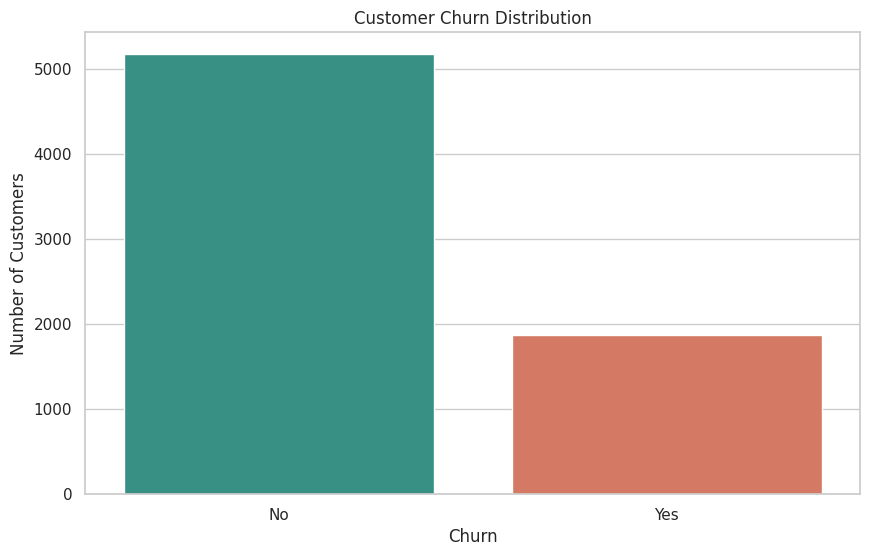

In [4]:
print(df['Churn'].value_counts())
print((df['Churn'].value_counts(normalize=True) * 100).round(2))

sns.countplot(data=df, x='Churn', palette=['#2a9d8f', '#e76f51'])
plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')
plt.show()

**Observation:** About 73.46% of customers stayed (No) and 26.54% left (Yes). The classes are imbalanced, so accuracy alone can be misleading: a model that always predicts "No" would already reach about 73% accuracy. For this reason precision, recall and F1 score will be used in the evaluation.

### 1.4 Handling Missing Values

In [5]:
print("Null values:", df.isnull().sum().sum())

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print("Missing TotalCharges after conversion:", df['TotalCharges'].isnull().sum())
display(df[df['TotalCharges'].isnull()][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges']])

Null values: 0
Missing TotalCharges after conversion: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


**Observation:** Pandas first reported no null values, but `TotalCharges` contained blank spaces, which is why it was stored as text. After converting it to numeric, 11 values became missing. All 11 customers have `tenure` equal to 0, which means they are new customers who have not been billed yet.

In [6]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)
print("Remaining missing values:", df.isnull().sum().sum())

Remaining missing values: 0


The 11 missing values were filled with 0 instead of the mean or median, because a customer with zero months of service has logically paid nothing so far. After this step the dataset has no missing values.

### 1.5 Checking and Removing Duplicates

In [7]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df['customerID'].duplicated().sum())
df.drop_duplicates(inplace=True)
print("Shape:", df.shape)

Duplicate rows: 0
Duplicate customer IDs: 0
Shape: (7043, 21)


No duplicate rows were found and every `customerID` is unique, so each row represents a different customer and no rows were removed.

### 1.6 Dropping an Unnecessary Column

In [8]:
df.drop(columns='customerID', inplace=True)
print("Columns now:", df.shape[1])

Columns now: 20


`customerID` is only an identifier and carries no information about customer behavior. Keeping it could make the model memorize individual customers instead of learning general patterns, so it was dropped.

### 1.7 Feature Engineering

In [9]:
service_cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                'TechSupport', 'StreamingTV', 'StreamingMovies']
df['num_services'] = (df[service_cols] == 'Yes').sum(axis=1)
df['is_auto_pay'] = df['PaymentMethod'].str.contains('automatic').astype(int)
display(df[['num_services', 'is_auto_pay']].describe())

,num_services,is_auto_pay
count,7043.000000,7043.000000
mean,2.037910,0.435326
std,1.847682,0.495835
min,0.000000,0.000000
25%,0.000000,0.000000
50%,2.000000,0.000000
75%,3.000000,1.000000
max,6.000000,1.000000


Two new features were created from existing columns:
- `num_services`: the number of extra services (security, backup, protection, support, streaming) a customer uses. Customers with more services may be more attached to the company.
- `is_auto_pay`: 1 if the customer pays by an automatic method (bank transfer or credit card), otherwise 0. Automatic payment may make customers less likely to leave.

Such features can give the models information that is not directly visible in the original columns.

### 1.8 Encoding Categorical Features

In [10]:
df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})
df['gender'] = df['gender'].map({'Female': 0, 'Male': 1})
for c in ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']:
    df[c] = df[c].map({'No': 0, 'Yes': 1})

cat_cols = df.select_dtypes(include='object').columns.tolist()
print("One-hot columns:", cat_cols)

df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)
print("Shape after encoding:", df_encoded.shape)

One-hot columns: ['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod']
Shape after encoding: (7043, 33)


Machine learning models need numbers, not text. Columns with two categories (Churn, gender, Partner, Dependents, PhoneService, PaperlessBilling) were converted to 0 and 1. The remaining text columns with more than two categories (such as Contract, InternetService and PaymentMethod) were converted with one-hot encoding, which creates a separate 0/1 column for each category. `drop_first=True` removes one column per feature to avoid duplicated information. After encoding, the dataset has 33 columns (32 features and the target).

### 1.9 Splitting into Training and Testing Sets

In [11]:
X = df_encoded.drop(columns='Churn')
y = df_encoded['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate train:", round(y_train.mean()*100, 2), "| test:", round(y_test.mean()*100, 2))

Train: (5634, 32) | Test: (1409, 32)
Churn rate train: 26.54 | test: 26.54


The data was split into 80% for training (5,634 customers) and 20% for testing (1,409 customers). The models learn from the training set and are evaluated on the test set, which they have never seen, so the results show how well they work on new customers. `stratify=y` keeps the churn ratio (about 26.5%) the same in both sets, and `random_state=42` makes the split reproducible.

### 1.10 Scaling Numerical Features

In [12]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'num_services']
scaler = StandardScaler()

X_train_s = X_train.copy()
X_test_s = X_test.copy()
X_train_s[num_cols] = scaler.fit_transform(X_train[num_cols])   # learn only from the training data
X_test_s[num_cols] = scaler.transform(X_test[num_cols])          # apply the same scaling to the test data

print(X_train_s[num_cols].mean().round(2))
print(X_train_s[num_cols].std().round(2))

tenure           -0.0
MonthlyCharges   -0.0
TotalCharges      0.0
num_services      0.0
dtype: float64
tenure            1.0
MonthlyCharges    1.0
TotalCharges      1.0
num_services      1.0
dtype: float64


The numerical columns were standardized (mean 0, standard deviation 1). This is important for distance-based and weight-based models such as KNN, SVM and Logistic Regression, because a large-valued column like `TotalCharges` (up to about 8,600) would otherwise dominate small-valued columns like `tenure`. Tree-based models are not affected by scaling.

The scaler was fitted **only on the training data** and then applied to the test data. If it were fitted on the full dataset, information from the test set would leak into training (data leakage) and the results would look better than they really are. For this reason the split was done before scaling.

### 1.11 Verifying the Preprocessed Data

In [13]:
print("Features:", X_train_s.shape[1])
print("Missing values in train:", X_train_s.isnull().sum().sum())
print("Missing values in test:", X_test_s.isnull().sum().sum())
display(X_train_s.head())

Features: 32
Missing values in train: 0
Missing values in test: 0


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,num_services,is_auto_pay,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
3738,1,0,0,0,0.102371,0,0,-0.521976,-0.262257,0.507935,0,1,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,1,0
3151,1,0,1,1,-0.711743,1,0,0.337478,-0.503635,-0.570530,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
4860,1,0,1,1,-0.793155,0,0,-0.809013,-0.749883,0.507935,0,1,0,0,0,0,1,0,1,0,0,0,1,0,0,0,0,0,1,0,0,1
3867,0,0,1,0,-0.263980,1,1,0.284384,-0.172722,1.047168,1,0,0,0,0,0,0,0,1,0,1,0,0,0,1,0,1,0,1,1,0,0
3810,1,0,1,1,-1.281624,1,0,-0.676279,-0.989374,-1.109762,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0


**Summary of preprocessing:** the blank `TotalCharges` values were converted and filled, no duplicates were found, the identifier column was dropped, two new features were created, all categorical columns were encoded, the data was split 80/20 with the same churn ratio in both parts, and the numerical features were scaled. The data is now ready for model training.

## 2. Model Development
### 2.0 Importing Models and Creating a Training Helper

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

trained = {}       # model name -> fitted model
train_time = {}    # model name -> training time in seconds
data_used = {}     # model name -> (X_train, X_test) used by that model

def train_model(name, model, X_tr, X_te):
    start = time.time()
    model.fit(X_tr, y_train)
    train_time[name] = round(time.time() - start, 3)
    trained[name] = model
    data_used[name] = (X_tr, X_te)
    tr_acc = model.score(X_tr, y_train)
    te_acc = model.score(X_te, y_test)
    print(f"{name}: trained in {train_time[name]} s | train accuracy = {tr_acc:.4f} | test accuracy = {te_acc:.4f}")

Six classification models were selected: Logistic Regression, Decision Tree, Random Forest, KNN, SVM and XGBoost. They cover different families of algorithms (linear, tree-based, distance-based, kernel-based and boosting), which makes the comparison meaningful.

A helper function trains each model, measures the **training time** and prints the training and testing accuracy. Comparing the two accuracies also shows whether a model is overfitting (very high training accuracy but much lower testing accuracy). Models that need scaling (Logistic Regression, KNN, SVM) use the scaled data, while tree-based models use the original data because scaling does not affect them.

### 2.1 Logistic Regression

In [15]:
lr = LogisticRegression(max_iter=1000, random_state=42)
train_model('Logistic Regression', lr, X_train_s, X_test_s)

Logistic Regression: trained in 0.105 s | train accuracy = 0.8055 | test accuracy = 0.8062


Logistic Regression is a linear model for classification. It calculates a weighted sum of the features and converts it into a probability between 0 and 1 using the sigmoid function. If the probability is above 0.5, the customer is predicted to churn. It is simple, fast and easy to interpret, because each feature has a coefficient that shows its effect. It was trained on the scaled data, and `max_iter=1000` gives the algorithm enough iterations to converge. It will act as the baseline model.

### 2.2 Decision Tree

In [16]:
dt = DecisionTreeClassifier(random_state=42)
train_model('Decision Tree', dt, X_train, X_test)
print("Tree depth:", dt.get_depth(), "| Number of leaves:", dt.get_n_leaves())

Decision Tree: trained in 0.091 s | train accuracy = 0.9980 | test accuracy = 0.7402
Tree depth: 30 | Number of leaves: 1112


A Decision Tree splits the data again and again with yes/no questions on the features (for example "is the contract month-to-month?") until it reaches a prediction. It is very easy to understand and needs no scaling. This tree was trained without any depth limit, so it can grow very deep and memorize the training data. This is called overfitting: the training accuracy becomes very high while the testing accuracy is much lower. This weakness is the reason ensemble models such as Random Forest were developed, and it can also be reduced by hyperparameter tuning in the bonus section.

**Observation:** The Decision Tree reached 99.80% training accuracy but only 74.02% testing accuracy, a gap of 25.78 points. Its depth is 30 with 1,112 leaves, so it has memorized the training data instead of learning general patterns. Its test accuracy is only slightly above the 73.46% that a model would get by always predicting "No churn".

### 2.3 Random Forest

In [17]:
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
train_model('Random Forest', rf, X_train, X_test)

Random Forest: trained in 1.366 s | train accuracy = 0.9980 | test accuracy = 0.7885


A Random Forest builds many decision trees (here 100), each trained on a random sample of the rows and a random subset of the features, and combines their votes. Because the individual errors of the trees partly cancel each other, the forest is usually more accurate and less prone to overfitting than a single tree. It handles mixed feature types well and can also show which features matter most. The disadvantages are that it takes longer to train and is harder to interpret than one tree.

**Observation:** The Random Forest also overfits (99.80% training vs 78.85% testing accuracy), but it generalizes much better than a single tree (78.85% vs 74.02%), which shows the benefit of combining many trees.

### 2.4 K-Nearest Neighbors (KNN)

In [18]:
knn = KNeighborsClassifier(n_neighbors=5)
train_model('KNN', knn, X_train_s, X_test_s)

KNN: trained in 0.009 s | train accuracy = 0.8387 | test accuracy = 0.7630


KNN does not learn a formula. It stores the training data and, for a new customer, finds the 5 most similar customers (the nearest neighbors, measured by distance) and predicts the most common class among them. Because it depends on distances, it must use the scaled data. Its training time is almost zero, since it only stores the data, but prediction is slower because the distance to every training customer must be calculated. It can also be affected by the many binary columns created by one-hot encoding.

### 2.5 Support Vector Machine (SVM)

In [19]:
svm = SVC(kernel='rbf', probability=True, random_state=42)
train_model('SVM', svm, X_train_s, X_test_s)

SVM: trained in 16.868 s | train accuracy = 0.8174 | test accuracy = 0.7963


A Support Vector Machine tries to find the boundary that separates the two classes with the largest possible margin. With the RBF kernel, it can create curved (non-linear) boundaries. It works well on scaled data and in high-dimensional spaces. `probability=True` is set so that class probabilities can be used later for evaluation, but it makes training slower. SVM is usually the slowest model on larger datasets and is difficult to interpret.

### 2.6 XGBoost (Optional Model)

In [20]:
xgb = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3,
                    random_state=42, eval_metric='logloss')
train_model('XGBoost', xgb, X_train, X_test)

XGBoost: trained in 0.104 s | train accuracy = 0.8198 | test accuracy = 0.7999


XGBoost is a gradient boosting algorithm. Unlike Random Forest, where trees are built independently, XGBoost builds trees one after another, and each new tree tries to correct the mistakes of the previous ones. It is often one of the best-performing algorithms on tabular data. A small `max_depth` of 3 and a learning rate of 0.1 keep the trees simple and reduce overfitting. It needs no scaling, but it has many hyperparameters to tune.

### 2.7 Summary of Trained Models

In [21]:
summary = pd.DataFrame({
    'Model': list(trained.keys()),
    'Training Time (s)': [train_time[m] for m in trained],
    'Train Accuracy': [round(trained[m].score(data_used[m][0], y_train), 4) for m in trained],
    'Test Accuracy': [round(trained[m].score(data_used[m][1], y_test), 4) for m in trained]
})
summary['Gap (Train - Test)'] = (summary['Train Accuracy'] - summary['Test Accuracy']).round(4)
display(summary)

,Model,Training Time (s),Train Accuracy,Test Accuracy,Gap (Train - Test)
0,Logistic Regression,0.105,0.8055,0.8062,-0.0007
1,Decision Tree,0.091,0.9980,0.7402,0.2578
2,Random Forest,1.366,0.9980,0.7885,0.2095
3,KNN,0.009,0.8387,0.7630,0.0757
4,SVM,16.868,0.8174,0.7963,0.0211
5,XGBoost,0.104,0.8198,0.7999,0.0199


All six models were trained successfully. The table shows the training time, training accuracy, testing accuracy and the gap between the two accuracies. A large gap means that the model has memorized the training data (overfitting). A full evaluation with precision, recall, F1 score and confusion matrices follows in Section 3, because accuracy alone is not enough for this imbalanced dataset.

**Observation:**
- Logistic Regression has the highest testing accuracy (80.62%) and almost no gap between training and testing accuracy, so it generalizes very well.
- XGBoost (79.99%) and SVM (79.63%) follow closely with small gaps (1.99 and 2.11 points). SVM is the slowest model (about 9.5 s), while XGBoost is fast (about 0.14 s).
- KNN is the fastest to train (about 0.01 s) but is less accurate (76.30%).
- Decision Tree and Random Forest overfit strongly (gaps of 25.78 and 20.95 points).
- The differences between the top three models are small, and the baseline is 73.46%, so accuracy alone is not enough. Precision, recall and F1 score are needed in the next section.

## 3. Model Evaluation
### 3.0 Evaluation Metrics Used

In [22]:
import os
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, roc_auc_score)

IMG = '/content/drive/MyDrive/Task_02_AI_ML/images/'
os.makedirs(IMG, exist_ok=True)
print("Metrics imported. Images will be saved in:", IMG)

Metrics imported. Images will be saved in: /content/drive/MyDrive/Task_02_AI_ML/images/


The following metrics are used. In all of them the positive class is "Churn = Yes".

- **Accuracy** = correct predictions / all predictions. It is misleading on imbalanced data.
- **Precision** = TP / (TP + FP). Of the customers predicted to churn, how many really churned? Low precision means the company wastes retention offers on loyal customers.
- **Recall** = TP / (TP + FN). Of the customers who really churned, how many did the model find? Low recall means many leaving customers are missed.
- **F1 Score** = the harmonic mean of precision and recall. It balances the two.
- **Confusion Matrix** = a table of True Negatives (TN), False Positives (FP), False Negatives (FN) and True Positives (TP).
- **ROC-AUC** = how well the model ranks churners above non-churners (1.0 is perfect, 0.5 is random guessing).

For churn prediction, **recall** is especially important, because losing a customer is more costly than sending an offer to a customer who would have stayed.

### 3.1 Calculating the Metrics

In [23]:
results, preds = [], {}
for name, model in trained.items():
    X_te = data_used[name][1]
    y_pred = model.predict(X_te)
    y_prob = model.predict_proba(X_te)[:, 1]
    preds[name] = y_pred
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).round(4).set_index('Model')
display(results_df.sort_values('F1 Score', ascending=False))

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,
Logistic Regression,0.8062,0.6593,0.5588,0.6049,0.8422
XGBoost,0.7999,0.6544,0.5214,0.5804,0.8442
SVM,0.7963,0.6537,0.4947,0.5632,0.7955
Random Forest,0.7885,0.6275,0.5000,0.5565,0.8217
KNN,0.7630,0.5565,0.5267,0.5412,0.7783
Decision Tree,0.7402,0.5109,0.5027,0.5067,0.6641


All metrics were calculated on the test set (1,409 customers) that the models have never seen. The table is sorted by F1 score, because F1 balances precision and recall and is more reliable than accuracy for this imbalanced dataset.

**Observation:**
- Logistic Regression is the best model on accuracy (80.62%), precision (65.93%), recall (55.88%) and F1 score (60.49%).
- XGBoost has the highest ROC-AUC (0.8442), but only slightly above Logistic Regression (0.8422), so both rank churners well.
- SVM and XGBoost have similar precision (about 65%) but lower recall (49.47% and 52.14%), so they miss more churners.
- The Decision Tree is the weakest model (F1 score 50.67%, ROC-AUC 0.6641), which agrees with its strong overfitting.
- Even the best recall is only 55.88%, so about 44% of churners are still missed at the default threshold of 0.5.

### 3.2 Confusion Matrices

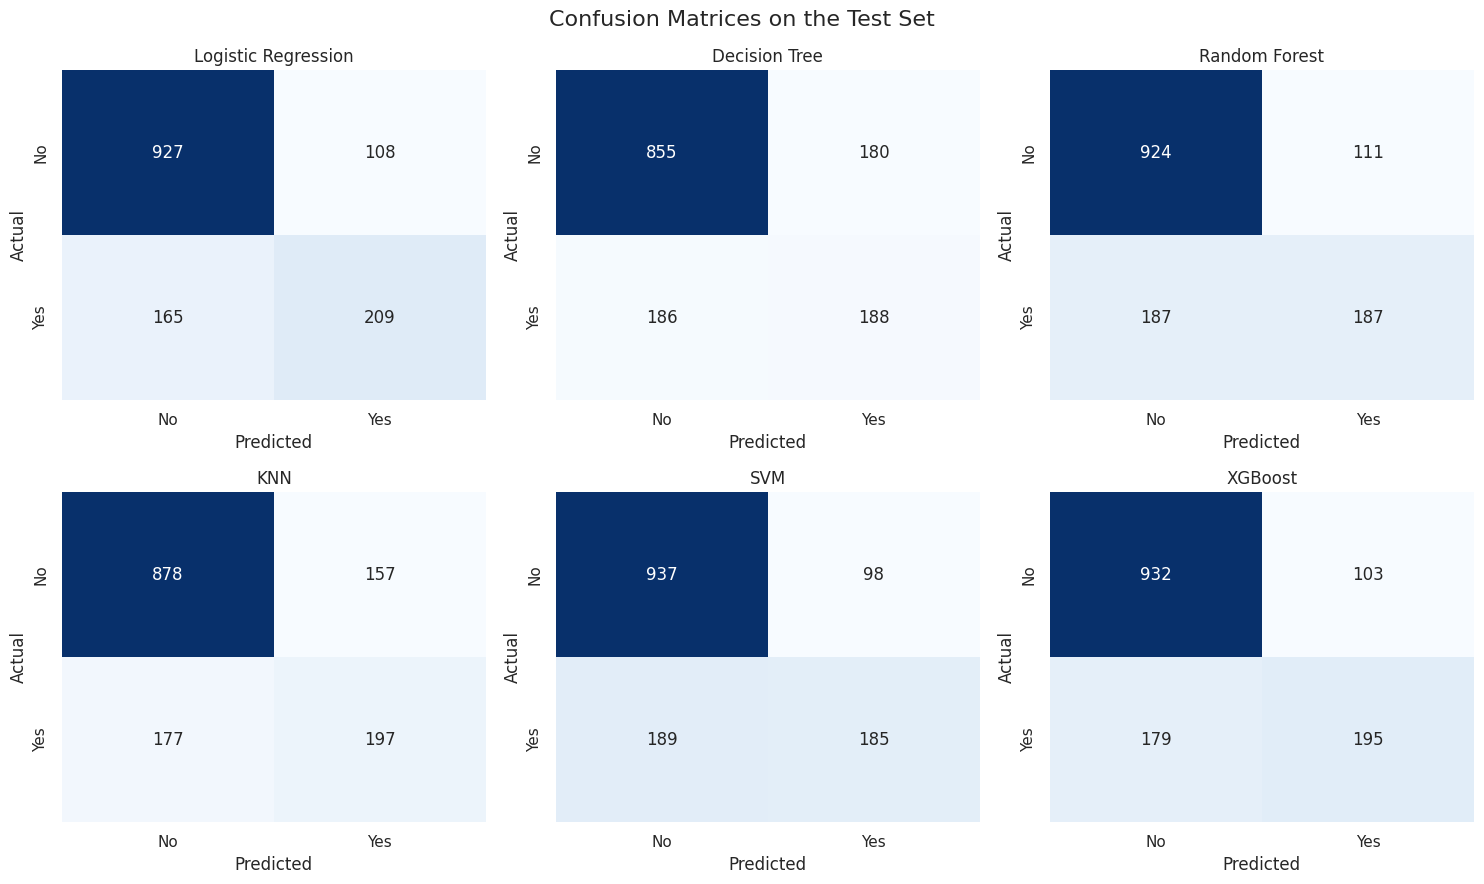

,TN,FP,FN,TP
Model,,,,
Logistic Regression,927,108,165,209
Decision Tree,855,180,186,188
Random Forest,924,111,187,187
KNN,878,157,177,197
SVM,937,98,189,185
XGBoost,932,103,179,195


In [24]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, y_pred) in zip(axes.ravel(), preds.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.suptitle('Confusion Matrices on the Test Set', fontsize=16)
plt.tight_layout()
plt.savefig(IMG + 'confusion_matrices.png', dpi=300, bbox_inches='tight')
plt.show()

cm_rows = []
for name, y_pred in preds.items():
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    cm_rows.append({'Model': name, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp})
display(pd.DataFrame(cm_rows).set_index('Model'))

In each matrix, the rows show the actual class and the columns show the predicted class. TN are loyal customers correctly identified, TP are churners correctly found, FP are loyal customers wrongly flagged as churners, and FN are churners that the model missed. For this business problem, False Negatives (missed churners) are the most costly error.

**Observation:** The test set contains 374 customers who actually churned. Logistic Regression finds 209 of them (TP) and misses 165 (FN), while SVM finds only 185 and misses 189. SVM makes the fewest false alarms (98 FP), but it pays for this with the most missed churners. Logistic Regression flags 108 loyal customers by mistake, which is a fair price for catching more churners. Since a lost customer is more costly than an unnecessary retention offer, models with fewer False Negatives are preferred.

### 3.3 Comparing the Metrics and Checking Overfitting

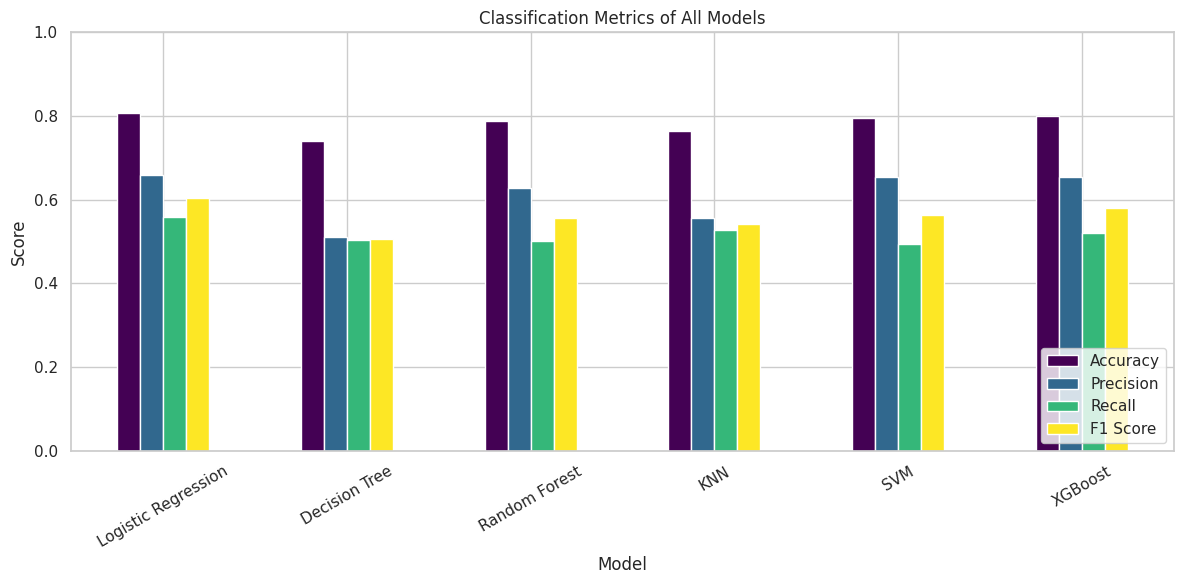

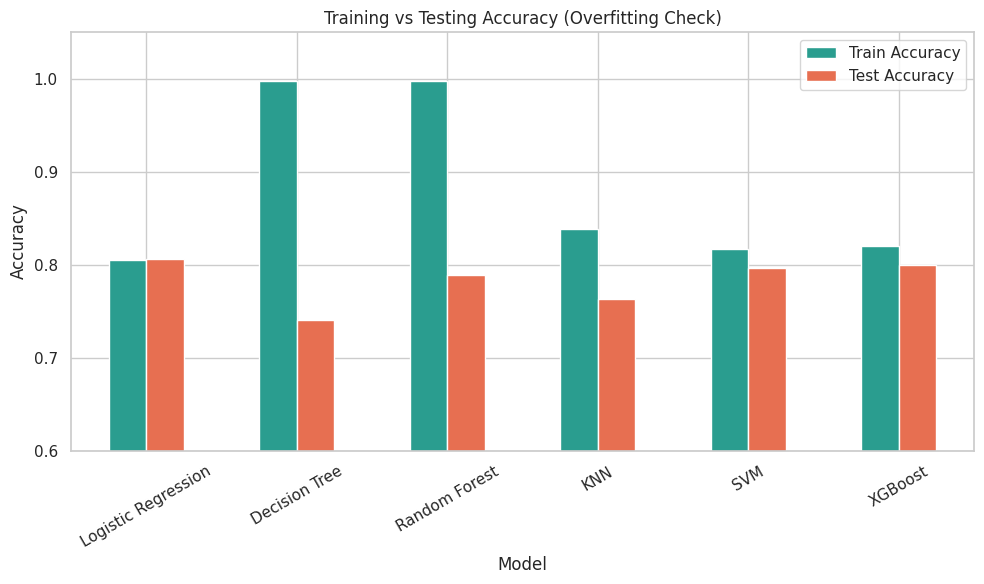

In [25]:
results_df[['Accuracy', 'Precision', 'Recall', 'F1 Score']].plot(kind='bar', figsize=(12, 6), colormap='viridis')
plt.title('Classification Metrics of All Models')
plt.xlabel('Model'); plt.ylabel('Score'); plt.ylim(0, 1)
plt.xticks(rotation=30); plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig(IMG + 'metrics_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

summary.set_index('Model')[['Train Accuracy', 'Test Accuracy']].plot(kind='bar', figsize=(10, 6), color=['#2a9d8f', '#e76f51'])
plt.title('Training vs Testing Accuracy (Overfitting Check)')
plt.xlabel('Model'); plt.ylabel('Accuracy'); plt.ylim(0.6, 1.05)
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(IMG + 'train_vs_test.png', dpi=300, bbox_inches='tight')
plt.show()

**Observation:** The metrics chart shows that Logistic Regression has the highest bars on all four metrics, while the Decision Tree has the lowest. In all models recall and F1 are clearly below accuracy, which confirms that accuracy alone hides the weak detection of churners. The training vs testing chart shows that Logistic Regression, SVM and XGBoost have nearly equal training and testing accuracy, whereas the Decision Tree and Random Forest score almost 100% on training data but much lower on test data, which is a clear sign of overfitting.

## 3B. Regression Task: Predicting Monthly Charges
### 3B.1 Preparing the Regression Data

In [26]:
X_reg = df_encoded.drop(columns=['MonthlyCharges', 'TotalCharges', 'Churn'])
y_reg = df_encoded['MonthlyCharges']

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42)

reg_cols = ['tenure', 'num_services']
reg_scaler = StandardScaler()
Xr_train_s = Xr_train.copy()
Xr_test_s = Xr_test.copy()
Xr_train_s[reg_cols] = reg_scaler.fit_transform(Xr_train[reg_cols])
Xr_test_s[reg_cols] = reg_scaler.transform(Xr_test[reg_cols])

print("Train:", Xr_train.shape, "| Test:", Xr_test.shape)
print("MonthlyCharges: mean =", round(y_reg.mean(), 2), "| min =", y_reg.min(), "| max =", y_reg.max())

Train: (5634, 30) | Test: (1409, 30)
MonthlyCharges: mean = 64.76 | min = 18.25 | max = 118.75


To cover regression metrics, a second task was added: predicting the continuous value `MonthlyCharges` (the monthly bill of a customer). `TotalCharges` was removed from the features because it is almost `tenure × MonthlyCharges`, so it would give away the answer (data leakage). `Churn` was also removed because it is not a pricing feature. The data was split 80/20 and the numerical features were scaled using the training data only, as before.

### 3B.2 Training Regression Models and Calculating Metrics

In [27]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

reg_models = {
    'Linear Regression': (LinearRegression(), True),
    'Decision Tree': (DecisionTreeRegressor(max_depth=8, random_state=42), False),
    'Random Forest': (RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1), False),
    'XGBoost': (XGBRegressor(n_estimators=200, learning_rate=0.1, max_depth=4, random_state=42), False)
}

reg_results, reg_preds = [], {}
for name, (model, scaled) in reg_models.items():
    Xtr, Xte = (Xr_train_s, Xr_test_s) if scaled else (Xr_train, Xr_test)
    start = time.time()
    model.fit(Xtr, yr_train)
    t = round(time.time() - start, 3)
    pred = model.predict(Xte)
    reg_preds[name] = pred
    mse = mean_squared_error(yr_test, pred)
    reg_results.append({
        'Model': name,
        'Training Time (s)': t,
        'MAE': mean_absolute_error(yr_test, pred),
        'MSE': mse,
        'RMSE': np.sqrt(mse),
        'R2 Score': r2_score(yr_test, pred)
    })

reg_df = pd.DataFrame(reg_results).round(4).set_index('Model')
display(reg_df.sort_values('R2 Score', ascending=False))

,Training Time (s),MAE,MSE,RMSE,R2 Score
Model,,,,,
Linear Regression,0.013,0.7893,1.1052,1.0513,0.9988
XGBoost,0.195,0.8193,1.1977,1.0944,0.9987
Random Forest,1.744,0.8966,1.4211,1.1921,0.9984
Decision Tree,0.024,0.9436,1.7080,1.3069,0.9981


Four regression models were trained and evaluated on the test set with four metrics:
- **MAE** (Mean Absolute Error): the average size of the error in the original unit (dollars per month).
- **MSE** (Mean Squared Error): the average of squared errors; it punishes large errors more.
- **RMSE** (Root Mean Squared Error): the square root of MSE, again in dollars, so it is easy to interpret.
- **R² Score**: the share of the variation in monthly charges that the model explains (1.0 is perfect, 0 means no better than predicting the average).

The Decision Tree depth was limited to 8 to reduce overfitting.

**Observation:**
- Linear Regression is the best regression model on every metric: MAE 0.7893, MSE 1.1052, RMSE 1.0513 and R² 0.9988. On average its prediction is only about 0.79 dollars away from the real monthly bill.
- XGBoost (R² 0.9987), Random Forest (0.9984) and the Decision Tree (0.9981) are very close, so all four models predict the monthly bill almost perfectly.
- Linear Regression is also one of the fastest models (0.025 s), while Random Forest is the slowest (2.52 s).
- The very high R² is not a sign of a mistake. `TotalCharges` and `Churn` were removed, but the monthly bill of a telecom customer is built from fixed prices of the services they use (phone, internet type and add-ons). The service columns therefore explain the bill almost completely, and a simple linear model that adds up their effects works best.

### 3B.3 Actual vs Predicted Monthly Charges

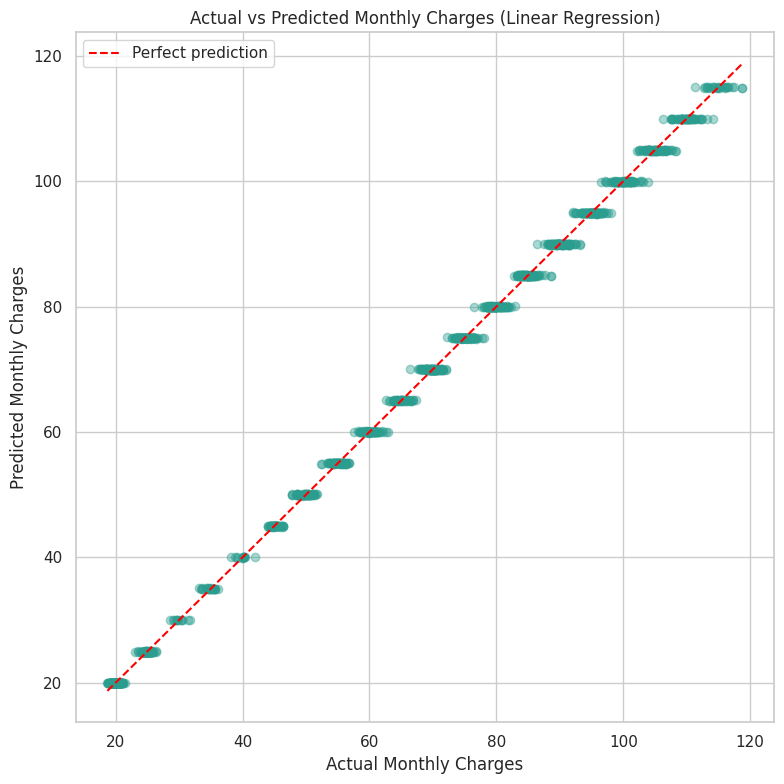

Best regression model: Linear Regression


In [28]:
best_reg = reg_df['R2 Score'].idxmax()
plt.figure(figsize=(8, 8))
plt.scatter(yr_test, reg_preds[best_reg], alpha=0.4, color='#2a9d8f')
lims = [yr_test.min(), yr_test.max()]
plt.plot(lims, lims, color='red', linestyle='--', label='Perfect prediction')
plt.title(f'Actual vs Predicted Monthly Charges ({best_reg})')
plt.xlabel('Actual Monthly Charges')
plt.ylabel('Predicted Monthly Charges')
plt.legend()
plt.tight_layout()
plt.savefig(IMG + 'regression_actual_vs_predicted.png', dpi=300, bbox_inches='tight')
plt.show()
print("Best regression model:", best_reg)

**Observation:** The points of the Linear Regression model lie very close to the red "perfect prediction" line over the whole range from about 20 to 120 dollars. The horizontal bands appear because many plans have prices that are multiples of about 5 dollars. There is no curve or fan shape, which shows that the model is accurate at both low and high bills and that the relationship between the features and the monthly charges is linear.

## 4. Model Comparison
### 4.1 Classification Models: Comparison Table

In [29]:
advantages = {
    'Logistic Regression': 'Simple, fast, easy to interpret, no overfitting here, best F1 score',
    'XGBoost': 'High ROC-AUC, fast training, handles complex patterns, small train-test gap',
    'SVM': 'Good precision, works well in high-dimensional scaled data, small gap',
    'Random Forest': 'Combines many trees, much better than a single tree, gives feature importance',
    'KNN': 'Very simple, almost no training time, no assumptions about the data',
    'Decision Tree': 'Very easy to understand and visualize, no scaling needed'
}
limitations = {
    'Logistic Regression': 'Only linear boundaries, recall is still only about 56%',
    'XGBoost': 'Many hyperparameters to tune, lower recall than Logistic Regression',
    'SVM': 'Slowest to train (several seconds), lowest recall among top models, hard to interpret',
    'Random Forest': 'Strong overfitting (99.8% train accuracy), slower, harder to interpret',
    'KNN': 'Slow predictions on large data, sensitive to scaling and many binary columns',
    'Decision Tree': 'Severe overfitting (gap of 25.78 points), unstable, lowest ROC-AUC'
}

comparison = results_df.copy()
comparison.insert(0, 'Training Time (s)', [train_time[m] for m in comparison.index])
comparison = comparison.sort_values('F1 Score', ascending=False)
comparison.insert(0, 'Rank', range(1, len(comparison) + 1))
comparison['Advantages'] = comparison.index.map(advantages)
comparison['Limitations'] = comparison.index.map(limitations)

pd.set_option('display.max_colwidth', None)
display(comparison.style.set_properties(subset=['Advantages', 'Limitations'],
        **{'text-align': 'left', 'white-space': 'normal', 'min-width': '260px'}))

comparison.to_csv(IMG + 'classification_comparison.csv')

,Rank,Training Time (s),Accuracy,Precision,Recall,F1 Score,ROC-AUC,Advantages,Limitations
Model,,,,,,,,,
Logistic Regression,1,0.105000,0.806200,0.659300,0.558800,0.604900,0.842200,"Simple, fast, easy to interpret, no overfitting here, best F1 score","Only linear boundaries, recall is still only about 56%"
XGBoost,2,0.104000,0.799900,0.654400,0.521400,0.580400,0.844200,"High ROC-AUC, fast training, handles complex patterns, small train-test gap","Many hyperparameters to tune, lower recall than Logistic Regression"
SVM,3,16.868000,0.796300,0.653700,0.494700,0.563200,0.795500,"Good precision, works well in high-dimensional scaled data, small gap","Slowest to train (several seconds), lowest recall among top models, hard to interpret"
Random Forest,4,1.366000,0.788500,0.627500,0.500000,0.556500,0.821700,"Combines many trees, much better than a single tree, gives feature importance","Strong overfitting (99.8% train accuracy), slower, harder to interpret"
KNN,5,0.009000,0.763000,0.556500,0.526700,0.541200,0.778300,"Very simple, almost no training time, no assumptions about the data","Slow predictions on large data, sensitive to scaling and many binary columns"
Decision Tree,6,0.091000,0.740200,0.510900,0.502700,0.506700,0.664100,"Very easy to understand and visualize, no scaling needed","Severe overfitting (gap of 25.78 points), unstable, lowest ROC-AUC"


The table compares all six classification models by training time, evaluation metrics, advantages and limitations. The models are ranked by F1 score, because F1 balances precision and recall and is more reliable than accuracy on this imbalanced dataset (26.5% churn).

**Observation:**
- Logistic Regression ranks first (F1 score 0.6049), with the best accuracy (80.62%), precision (65.93%) and recall (55.88%). XGBoost is second (F1 0.5804) and has the highest ROC-AUC (0.8442). SVM is third (F1 0.5632).
- KNN has the highest recall among the lower-ranked models (52.67%), but its precision is the lowest of all models except the Decision Tree (55.65%), so its F1 score is only 0.5412.
- The Decision Tree is last on every important metric (F1 0.5067, ROC-AUC 0.6641).
- No model reaches a recall above 56%, so every model still misses more than 44% of the customers who leave. This shows the limits of the default settings and motivates hyperparameter tuning in the bonus section.

### 4.2 Training Time vs Performance

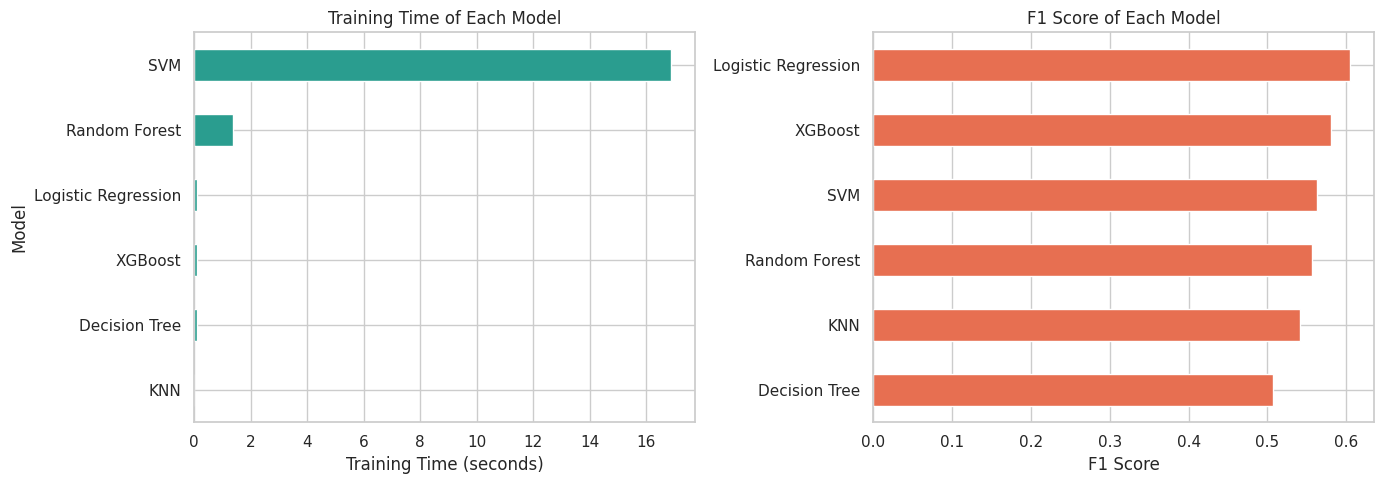

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

comparison['Training Time (s)'].sort_values().plot(kind='barh', color='#2a9d8f', ax=ax[0])
ax[0].set_title('Training Time of Each Model')
ax[0].set_xlabel('Training Time (seconds)')
ax[0].set_ylabel('Model')

comparison['F1 Score'].sort_values().plot(kind='barh', color='#e76f51', ax=ax[1])
ax[1].set_title('F1 Score of Each Model')
ax[1].set_xlabel('F1 Score')
ax[1].set_ylabel('')

plt.tight_layout()
plt.savefig(IMG + 'time_vs_f1.png', dpi=300, bbox_inches='tight')
plt.show()

**Observation:** SVM is by far the slowest model (about 9.5 seconds), followed by Random Forest (about 1.8 seconds). Logistic Regression, XGBoost and the Decision Tree train in a fraction of a second, and KNN is almost instant because it only stores the data. The fastest models are not the worst ones: Logistic Regression has the best F1 score and trains in about 0.13 seconds, so a longer training time does not mean better results here. Training times vary a little from run to run depending on the speed of the computer.

### 4.3 Regression Models: Comparison Table

In [31]:
reg_adv = {
    'Linear Regression': 'Best on all metrics, fastest to interpret, matches the additive pricing',
    'XGBoost': 'Very accurate, captures non-linear effects, fast',
    'Random Forest': 'Robust, handles non-linear effects, little overfitting',
    'Decision Tree': 'Easy to understand, very fast to train'
}
reg_lim = {
    'Linear Regression': 'Assumes a linear relationship, would struggle with strong non-linear effects',
    'XGBoost': 'Needs tuning, no gain over the simple linear model here',
    'Random Forest': 'Slowest to train (2.52 s) and not better than Linear Regression',
    'Decision Tree': 'Lowest accuracy of the four, depth must be limited'
}

reg_comparison = reg_df.sort_values('R2 Score', ascending=False).copy()
reg_comparison.insert(0, 'Rank', range(1, len(reg_comparison) + 1))
reg_comparison['Advantages'] = reg_comparison.index.map(reg_adv)
reg_comparison['Limitations'] = reg_comparison.index.map(reg_lim)

display(reg_comparison.style.set_properties(subset=['Advantages', 'Limitations'],
        **{'text-align': 'left', 'white-space': 'normal', 'min-width': '260px'}))

reg_comparison.to_csv(IMG + 'regression_comparison.csv')

,Rank,Training Time (s),MAE,MSE,RMSE,R2 Score,Advantages,Limitations
Model,,,,,,,,
Linear Regression,1,0.013000,0.789300,1.105200,1.051300,0.998800,"Best on all metrics, fastest to interpret, matches the additive pricing","Assumes a linear relationship, would struggle with strong non-linear effects"
XGBoost,2,0.195000,0.819300,1.197700,1.094400,0.998700,"Very accurate, captures non-linear effects, fast","Needs tuning, no gain over the simple linear model here"
Random Forest,3,1.744000,0.896600,1.421100,1.192100,0.998400,"Robust, handles non-linear effects, little overfitting",Slowest to train (2.52 s) and not better than Linear Regression
Decision Tree,4,0.024000,0.943600,1.708000,1.306900,0.998100,"Easy to understand, very fast to train","Lowest accuracy of the four, depth must be limited"


The regression models are ranked by R² score. All four models are very accurate, but Linear Regression is the best on every metric and also trains very quickly, so no complex model is needed for this task.

**Observation:** Linear Regression is ranked first on every regression metric (MAE 0.7893, RMSE 1.0513, R² 0.9988) and trains in 0.025 seconds. XGBoost, Random Forest and the Decision Tree are only slightly worse, but they are slower or less accurate, so the simplest model is the best choice for predicting monthly charges.

## 5. Bonus: Hyperparameter Tuning
### 5.1 Defining the Search Spaces

In [32]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
pos_weight = round((y_train == 0).sum() / (y_train == 1).sum(), 2)
print("Ratio of loyal to churn customers (for XGBoost):", pos_weight)

searches = {
    'Logistic Regression': (
        GridSearchCV(LogisticRegression(max_iter=2000, solver='liblinear', random_state=42),
                     {'C': [0.01, 0.1, 1, 10], 'penalty': ['l1', 'l2'],
                      'class_weight': [None, 'balanced']},
                     cv=cv, scoring='f1', n_jobs=-1),
        X_train_s, X_test_s),
    'Decision Tree': (
        GridSearchCV(DecisionTreeClassifier(random_state=42),
                     {'max_depth': [3, 5, 7, 10], 'min_samples_leaf': [1, 10, 30],
                      'class_weight': [None, 'balanced']},
                     cv=cv, scoring='f1', n_jobs=-1),
        X_train, X_test),
    'Random Forest': (
        GridSearchCV(RandomForestClassifier(random_state=42),
                     {'n_estimators': [100, 200], 'max_depth': [6, 10],
                      'min_samples_leaf': [3, 8], 'class_weight': [None, 'balanced']},
                     cv=cv, scoring='f1', n_jobs=-1),
        X_train, X_test),
    'XGBoost': (
        RandomizedSearchCV(XGBClassifier(random_state=42, eval_metric='logloss'),
                           {'n_estimators': [100, 200, 300], 'max_depth': [2, 3, 4, 5],
                            'learning_rate': [0.01, 0.05, 0.1, 0.2],
                            'subsample': [0.7, 0.85, 1.0], 'colsample_bytree': [0.7, 0.85, 1.0],
                            'scale_pos_weight': [1, pos_weight]},
                           n_iter=20, cv=cv, scoring='f1', random_state=42, n_jobs=-1),
        X_train, X_test)
}
print("Search spaces defined for:", list(searches.keys()))

Ratio of loyal to churn customers (for XGBoost): 2.77
Search spaces defined for: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'XGBoost']


Hyperparameters are settings that are chosen before training (for example the tree depth or the regularization strength) and that strongly influence a model. Four models were tuned:
- **GridSearchCV** (Logistic Regression, Decision Tree, Random Forest) tries every combination in a small grid.
- **RandomizedSearchCV** (XGBoost) tries 20 random combinations from a large space, which is much faster than testing all of them.

Each combination is evaluated with 5-fold stratified cross-validation on the **training data only**, and the **F1 score** is used for selection because the classes are imbalanced. The test set is not touched during tuning, so the final comparison is fair. `class_weight` and `scale_pos_weight` were included so that the models can pay more attention to the minority class (churners). SVM and KNN were not tuned because SVM is slow to train and KNN was already clearly weaker.

### 5.2 Running the Searches

In [33]:
tuned = {}
for name, (search, Xtr, Xte) in searches.items():
    start = time.time()
    search.fit(Xtr, y_train)
    secs = round(time.time() - start, 1)
    tuned[name] = (search.best_estimator_, Xte)
    print(f"{name} | best CV F1 = {search.best_score_:.4f} | search time = {secs} s")
    print("   Best parameters:", search.best_params_)

Logistic Regression | best CV F1 = 0.6313 | search time = 13.8 s
   Best parameters: {'C': 0.1, 'class_weight': 'balanced', 'penalty': 'l1'}
Decision Tree | best CV F1 = 0.6046 | search time = 2.6 s
   Best parameters: {'class_weight': 'balanced', 'max_depth': 7, 'min_samples_leaf': 30}
Random Forest | best CV F1 = 0.6397 | search time = 64.6 s
   Best parameters: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 8, 'n_estimators': 100}
XGBoost | best CV F1 = 0.6336 | search time = 19.7 s
   Best parameters: {'subsample': 0.85, 'scale_pos_weight': np.float64(2.77), 'n_estimators': 300, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 1.0}


For each model the search printed the best cross-validation F1 score and the best combination of hyperparameters. These tuned models are now compared with the original models on the test set.

**Observation:** The best combinations show what helps on this dataset. Logistic Regression, the Decision Tree and the Random Forest all selected `class_weight='balanced'`, and XGBoost selected `scale_pos_weight` = 2.77 (the ratio of loyal to churn customers), so all four models chose to pay more attention to the minority class. The Decision Tree preferred a shallow tree (depth 7, at least 30 samples per leaf) and the Random Forest a limited depth of 10 with at least 8 samples per leaf, which both reduce the overfitting seen earlier. Logistic Regression chose strong regularization (C = 0.1) with the L1 penalty. The best cross-validation F1 scores were: Random Forest 0.6397, XGBoost 0.6336, Logistic Regression 0.6313 and Decision Tree 0.6046. The Random Forest search was the slowest (75.5 s).

### 5.3 Comparing the Models Before and After Tuning

,Accuracy Before,Accuracy After,Precision Before,Precision After,Recall Before,Recall After,F1 Before,F1 After,AUC Before,AUC After,F1 Change,Recall Change
Model,,,,,,,,,,,,
Random Forest,0.7885,0.7622,0.6275,0.5360,0.5000,0.7754,0.5565,0.6339,0.8217,0.8424,0.0774,0.2754
XGBoost,0.7999,0.7445,0.6544,0.5121,0.5214,0.7914,0.5804,0.6218,0.8442,0.8438,0.0414,0.2700
Logistic Regression,0.8062,0.7438,0.6593,0.5113,0.5588,0.7834,0.6049,0.6188,0.8422,0.8407,0.0139,0.2246
Decision Tree,0.7402,0.7268,0.5109,0.4909,0.5027,0.7941,0.5067,0.6067,0.6641,0.8294,0.1000,0.2914


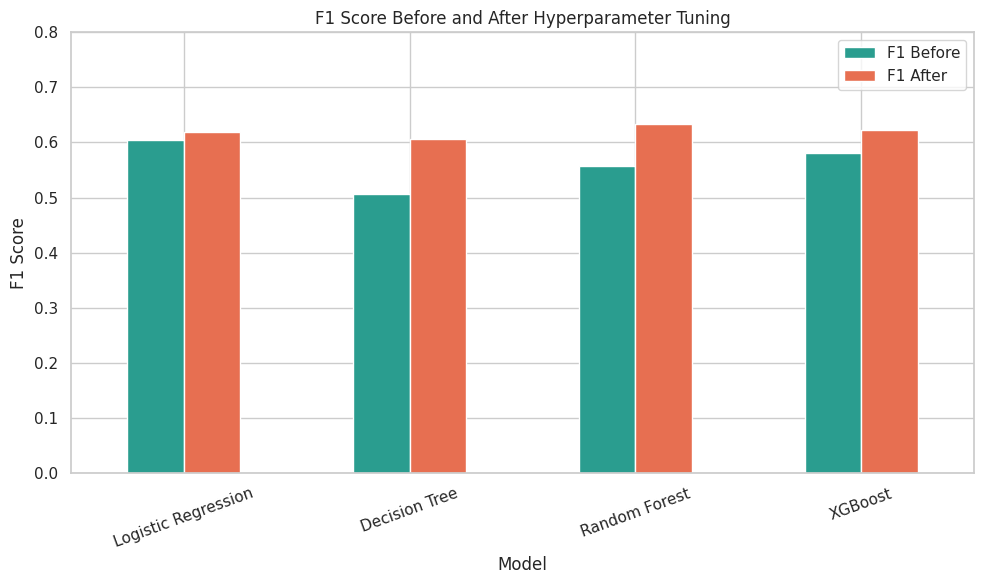

In [34]:
rows = []
for name, (best, Xte) in tuned.items():
    y_pred = best.predict(Xte)
    y_prob = best.predict_proba(Xte)[:, 1]
    b = results_df.loc[name]
    rows.append({
        'Model': name,
        'Accuracy Before': b['Accuracy'], 'Accuracy After': accuracy_score(y_test, y_pred),
        'Precision Before': b['Precision'], 'Precision After': precision_score(y_test, y_pred),
        'Recall Before': b['Recall'], 'Recall After': recall_score(y_test, y_pred),
        'F1 Before': b['F1 Score'], 'F1 After': f1_score(y_test, y_pred),
        'AUC Before': b['ROC-AUC'], 'AUC After': roc_auc_score(y_test, y_prob)
    })

tune_df = pd.DataFrame(rows).set_index('Model').round(4)
tune_df['F1 Change'] = (tune_df['F1 After'] - tune_df['F1 Before']).round(4)
tune_df['Recall Change'] = (tune_df['Recall After'] - tune_df['Recall Before']).round(4)
display(tune_df.sort_values('F1 After', ascending=False))
tune_df.to_csv(IMG + 'tuning_comparison.csv')

tune_df[['F1 Before', 'F1 After']].plot(kind='bar', figsize=(10, 6), color=['#2a9d8f', '#e76f51'])
plt.title('F1 Score Before and After Hyperparameter Tuning')
plt.xlabel('Model'); plt.ylabel('F1 Score'); plt.ylim(0, 0.8)
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(IMG + 'tuning_f1_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

**Observation:**
- Tuning improved the F1 score of all four models: Decision Tree +0.1000 (0.5067 to 0.6067), Random Forest +0.0774 (0.5565 to 0.6339), XGBoost +0.0414 (0.5804 to 0.6218) and Logistic Regression +0.0139 (0.6049 to 0.6188).
- The Random Forest became the best model with the highest F1 score (0.6339), which agrees with the cross-validation ranking (Random Forest first, then XGBoost, Logistic Regression and Decision Tree).
- Recall increased strongly for every model, from about 50-56% to 77.5-79.4%, so the tuned models find about 78% of the customers who leave instead of about half.
- This gain has a price: precision fell (for example Random Forest from 62.75% to 53.60%) and accuracy dropped for all models (Logistic Regression from 80.62% to 74.38%). The models now flag more customers as churners, so some loyal customers receive a retention offer unnecessarily. This is acceptable when losing a customer is more costly than an unnecessary offer.
- ROC-AUC shows what really improved. For Logistic Regression (0.8422 to 0.8407) and XGBoost (0.8442 to 0.8438) it stayed almost the same, which means their ability to rank customers did not change; the gain in recall mostly comes from the class weights that move the decision towards "churn". For the Random Forest (0.8217 to 0.8424) and the Decision Tree (0.6641 to 0.8294) AUC clearly increased, because limiting the depth and leaf size removed most of their overfitting.
- The differences between the top three tuned models (F1 between 0.6188 and 0.6339) are small, so the choice also depends on speed and interpretability.

### 5.4 Analysis of the Best Tuned Model

Best model: Random Forest | TN=784 | FP=251 | FN=84 | TP=290
tenure                            0.1707
Contract_Two year                 0.1304
TotalCharges                      0.1176
MonthlyCharges                    0.0802
InternetService_Fiber optic       0.0652
PaymentMethod_Electronic check    0.0633
Contract_One year                 0.0462
OnlineSecurity_Yes                0.0270
num_services                      0.0261
TechSupport_Yes                   0.0258
dtype: float64


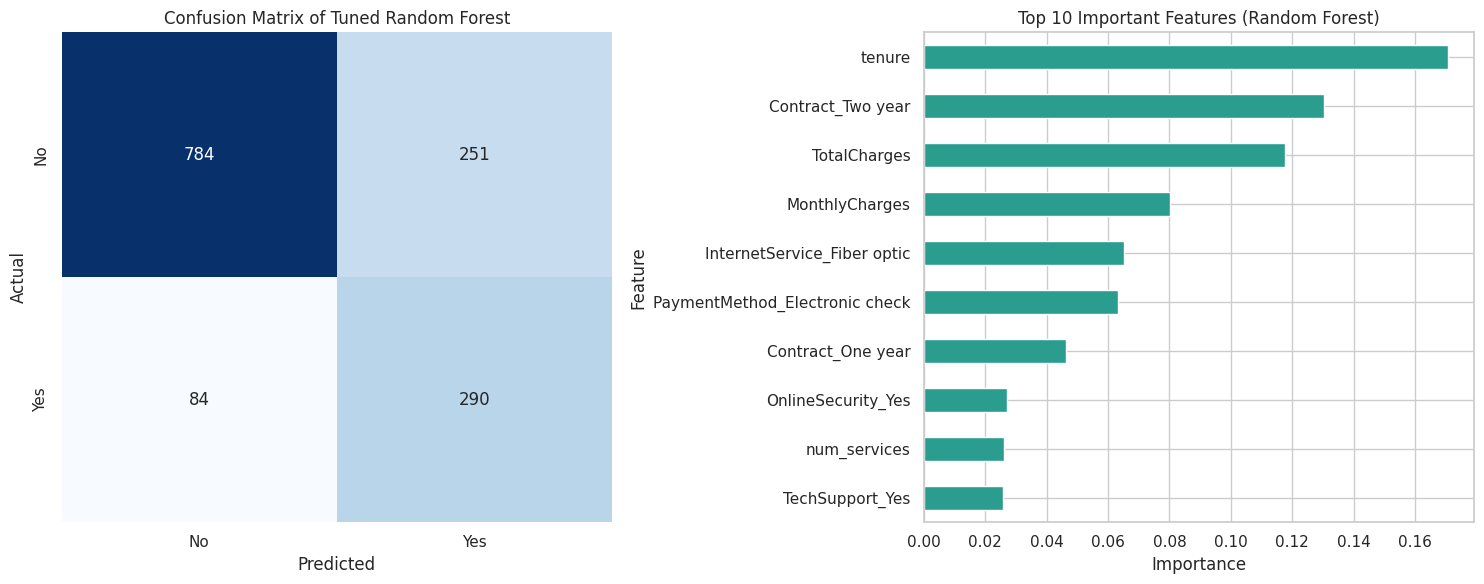

In [35]:
best_name = tune_df['F1 After'].idxmax()
best_model, Xte_best = tuned[best_name]
y_pred_best = best_model.predict(Xte_best)
cm_best = confusion_matrix(y_test, y_pred_best)
tn, fp, fn, tp = cm_best.ravel()
print(f"Best model: {best_name} | TN={tn} | FP={fp} | FN={fn} | TP={tp}")

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(cm_best, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax[0],
            xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
ax[0].set_title(f'Confusion Matrix of Tuned {best_name}')
ax[0].set_xlabel('Predicted'); ax[0].set_ylabel('Actual')

if hasattr(best_model, 'feature_importances_'):
    imp = pd.Series(best_model.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(10)
    imp[::-1].plot(kind='barh', color='#2a9d8f', ax=ax[1])
    ax[1].set_title(f'Top 10 Important Features ({best_name})')
    ax[1].set_xlabel('Importance'); ax[1].set_ylabel('Feature')
    print(imp.round(4))
plt.tight_layout()
plt.savefig(IMG + 'best_model_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

**Observation:**
- On the 1,409 test customers the tuned Random Forest produced 784 true negatives, 251 false positives, 84 false negatives and 290 true positives. It finds 290 of the 374 customers who actually churned (recall 77.54%) and misses 84 (22.46%).
- The default Random Forest found only 187 churners and missed 187. Tuning therefore found 103 more churners, at the cost of 140 additional false alarms (251 instead of 111 loyal customers flagged).
- The most important features are tenure (0.1707), a two-year contract (0.1304), TotalCharges (0.1176), MonthlyCharges (0.0802), fiber optic internet (0.0652) and payment by electronic check (0.0633). The top three together account for about 42% of the total importance.
- The engineered feature `num_services` is in the top ten (rank 9), which shows that feature engineering added useful information. `is_auto_pay` did not enter the top ten.
- Feature importance shows which features the model uses most, but not whether they increase or decrease churn.

### 5.5 Churn Rate by Key Features

In [36]:
for col in ['Contract', 'InternetService', 'PaymentMethod']:
    print((df.groupby(col)['Churn'].mean() * 100).round(2).sort_values(ascending=False), "\n")

df['tenure_group'] = pd.cut(df['tenure'], bins=[-1, 12, 24, 48, 72], labels=['0-12', '13-24', '25-48', '49-72'])
print((df.groupby('tenure_group', observed=False)['Churn'].mean() * 100).round(2))
df.drop(columns='tenure_group', inplace=True)

Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64 

InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: Churn, dtype: float64 

PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: Churn, dtype: float64 

tenure_group
0-12     47.44
13-24    28.71
25-48    20.39
49-72     9.51
Name: Churn, dtype: float64


**Observation:**
- **Contract type:** customers with a month-to-month contract churn at 42.71%, compared with 11.27% for a one-year contract and only 2.83% for a two-year contract. Month-to-month customers are about 15 times more likely to leave than two-year customers.
- **Tenure:** churn falls steadily as customers stay longer: 47.44% in the first 12 months, 28.71% for 13-24 months, 20.39% for 25-48 months and 9.51% for 49-72 months. The first year is the most dangerous period.
- **Internet service:** fiber optic customers churn at 41.89%, more than twice the rate of DSL customers (18.96%). Customers without internet service churn least (7.40%).
- **Payment method:** electronic check users churn at 45.29%, about three times more than customers who pay automatically by credit card (15.24%) or bank transfer (16.71%). This explains why `PaymentMethod_Electronic check` is among the most important features, and why the engineered feature `is_auto_pay` did not enter the top ten: the electronic check column already carries most of its information.
- These results agree with the feature importance of the Random Forest. Note that they show an association, not proof of cause: for example, fiber optic customers may churn because of higher prices or competition, which the data does not show.

## 6. Conclusion

**Problem and data.** The goal was to predict which telecom customers will churn, using the Telco Customer Churn dataset (7,043 customers, 21 columns, 26.54% churn). Preprocessing fixed the hidden missing values in `TotalCharges` (11 new customers with tenure 0, filled with 0), found no duplicates, dropped the identifier column, created two new features (`num_services` and `is_auto_pay`), encoded the categorical columns and split the data 80/20 with the same churn ratio in both parts. The numerical features were scaled after the split to avoid data leakage.

**Model comparison.** Six classifiers were trained and evaluated with accuracy, precision, recall, F1 score, ROC-AUC and confusion matrices. With default settings Logistic Regression was the best (accuracy 80.62%, F1 0.6049), while the Decision Tree and Random Forest overfitted strongly (99.80% training accuracy against 74.02% and 78.85% testing accuracy). However, every model found only about half of the churners (recall 49% to 56%), so accuracy alone was misleading. A second task, predicting `MonthlyCharges`, was used to cover regression metrics: Linear Regression was the best (MAE 0.79, RMSE 1.05, R² 0.9988), because the monthly bill is almost an additive sum of fixed service prices.

**Tuning and recommendation.** Hyperparameter tuning with GridSearchCV and RandomizedSearchCV (5-fold cross-validation, F1 score) improved all four tuned models. The **tuned Random Forest** is recommended as the best model: it has the highest F1 score on the test set (0.6339, up from 0.5565) and in cross-validation (0.6397), and it finds 77.54% of the churners (recall, up from 50.00%) with a ROC-AUC of 0.8424. It performed better than the other models because limiting its depth (10) and leaf size (at least 8 samples) removed the overfitting of the default forest, while class weights made it pay attention to the minority class, and because many trees capture non-linear patterns that Logistic Regression cannot. The price is lower precision (53.60%) and accuracy (76.22%), meaning that some loyal customers will receive a retention offer unnecessarily. This is acceptable because losing a customer costs more than an extra offer.

The most important features of the final model are customer tenure, a two-year contract and total charges, which together account for about 42% of the feature importance, followed by monthly charges, fiber optic internet and payment by electronic check. The data confirms the direction of these effects: month-to-month customers churn at 42.71% against 2.83% for two-year contracts, customers in their first year churn at 47.44% against 9.51% after four years, and electronic check users churn at 45.29%. The company could therefore reduce churn by focusing retention offers on new, month-to-month customers and by encouraging longer contracts and automatic payment.

The differences between the top three tuned models are small (F1 0.6188 to 0.6339), so Logistic Regression remains a good alternative when speed and interpretability matter most, and XGBoost has the highest ROC-AUC (0.8438). The main limitations are that a single train-test split was used and that precision is still modest. Future work could tune the decision threshold according to the real cost of a lost customer and test more features. Through this task I learned that preprocessing choices (such as avoiding data leakage), the right metrics for imbalanced data and careful tuning matter as much as the choice of algorithm.